# Profile: Ghent DSLIB v3.4 (real project database)

What is in the data, what is missing, how the values are spread, and what one project looks
like. The findings at the end decide how Module D (project controls) can use it.

| | |
|---|---|
| **What** | 231 real projects (construction and other sectors) with baseline schedules, costs and, for many, tracking periods with earned-value data. Collected by the OR&S group, Ghent University |
| **Source** | https://github.com/MarioVanhoucke/DSLIB-Dynamic-Scheduling-Empirical-Project-Library (release `DSLIB_v3.4`, published 2026-05-26) |
| **License** | The repository has **no license file** and the pages show no terms of use; the README asks users to cite the paper below |
| **Citation** | Batselier, J. & Vanhoucke, M. (2015). Construction and evaluation framework for a real-life project database. *International Journal of Project Management*, 33(3), 697–710. https://doi.org/10.1016/j.ijproman.2014.09.004. For the extended dataset also Vanhoucke (2023) *The illusion of control* and Vanhoucke (2024) *A quest for projects with scarce resources* |

Copied from [`data/DATA_CATALOG.md`](../data/DATA_CATALOG.md). Spec:
[`specs/2026-10-16-profiling-notebooks/`](../specs/2026-10-16-profiling-notebooks/spec.md).

Run headless (inside the container):
`uv run --with jupyterlab jupyter nbconvert --to notebook --execute --inplace notebooks/00_profile_ghent.ipynb`

Data is read through `load_ghent()` (`src/datasets/ghent.py`); nothing is changed or written.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.datasets.ghent import load_ghent
from src.datasets.profiling import missing_table

# openpyxl warns about an Excel extension it does not read (it does not affect the cell values)
warnings.filterwarnings("ignore", message="Unknown extension", module="openpyxl")
plt.rcParams.update({"figure.dpi": 72, "figure.figsize": (10, 3)})
pd.set_option("display.max_columns", 30, "display.width", 120)

data = load_ghent()
projects, activities, tracking, issues = (
    data.projects, data.activities, data.tracking, data.issues,
)  # fmt: skip

## 1. Counts

In [2]:
groups = projects["group"].value_counts().sort_index()
print(f"projects: {len(projects)}")
print("groups (A = tracking ready, B = raw progress only, C = plan only):", groups.to_dict())
leaf = activities[~activities["is_summary"]]
print(
    f"activities: {len(activities)} rows, {len(leaf)} leaf activities, "
    f"{int(activities['is_summary'].sum())} WBS summary rows"
)
print(f"tracking periods: {len(tracking)} in {tracking['project_id'].nunique()} projects")
print(f"loader issues: {len(issues)}")
projects["sector"].value_counts().rename("projects").to_frame()

projects: 231
groups (A = tracking ready, B = raw progress only, C = plan only): {'A': 117, 'B': 41, 'C': 73}
activities: 25626 rows, 21994 leaf activities, 3632 WBS summary rows
tracking periods: 1514 in 117 projects
loader issues: 221


,projects
sector,
Construction (civil),60
Construction (residential building),54
IT,31
Construction (commercial building),18
Construction (industrial),16
Event management,15
Construction (institutional building),15
Engineering,14
Mobility,6


## 2. Missing values

Missing cells per column (only columns with at least one gap are shown), then the problems the
loader recorded. Rows with problems are kept and listed, never silently dropped.

In [3]:
for name, table in [("projects", projects), ("activities", activities), ("tracking", tracking)]:
    gaps = missing_table(table).query("missing > 0")
    print(f"--- {name}: {len(table)} rows, {len(gaps)} of {table.shape[1]} columns have gaps")
    print(gaps.to_string(index=False) if len(gaps) else "no gaps")
print(f"loader issues: {len(issues)} in {issues['project_id'].nunique()} projects")

--- projects: 231 rows, 10 of 24 columns have gaps
            column  missing  missing_pct
          keywords       59        25.54
      submitted_by        1         0.43
               bac       31        13.42
     has_resources        5         2.16
     real_duration       76        32.90
         real_cost       76        32.90
duration_deviation       76        32.90
    cost_deviation       76        32.90
                ri       83        35.93
        regularity       83        35.93
--- activities: 25626 rows, 15 of 18 columns have gaps
         column  missing  missing_pct
           name        1         0.00
            wbs     1865         7.28
   predecessors     7478        29.18
     successors     9527        37.18
 baseline_start     1163         4.54
   baseline_end     5237        20.44
   duration_raw     1163         4.54
  duration_days     1163         4.54
 duration_hours     1163         4.54
resource_demand    19553        76.30
  resource_cost     8127 

In [4]:
issue_kinds = issues["problem"].str.replace(r":.*| \d+$", "", regex=True)
issue_table = pd.DataFrame(
    {
        "issues": issue_kinds.value_counts(),
        "projects": issues.groupby(issue_kinds)["project_id"].nunique(),
    }
)
issue_table

,issues,projects
problem,,
BAC missing,31,31
Fixed Cost not a number,13,1
Resources not Y/N,1,1
Variable Cost not a number,171,1
duplicate activity_id,1,1
no ID 0 row,4,4


## 3. Distributions

Project size, duration and budget (log scale: they span several orders of magnitude), then the
tracking data. "Last period" = the highest period number of each tracked project.

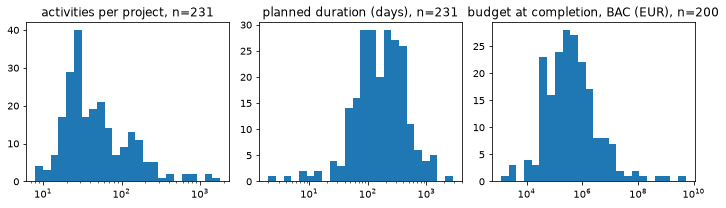

,n_activities,planned_duration_days,bac,real_duration,real_cost
count,231.0,231.0,2.000000e+02,155.0,155.0
mean,95.8,251.1,3.450837e+07,230.7,2895233.5
std,202.1,291.1,3.590391e+08,187.0,10297629.4
min,8.0,2.0,1.210000e+03,10.0,1780.0
25%,24.0,90.0,1.045485e+05,91.0,119978.4
50%,38.0,170.0,3.455131e+05,184.0,381678.0
75%,83.5,310.0,1.289020e+06,308.0,1315202.4
max,1796.0,2804.0,4.999958e+09,951.0,95509712.0


In [5]:
fig, axes = plt.subplots(1, 3)
for ax, col, title in [
    (axes[0], "n_activities", "activities per project"),
    (axes[1], "planned_duration_days", "planned duration (days)"),
    (axes[2], "bac", "budget at completion, BAC (EUR)"),
]:
    values = projects[col].dropna()
    values = values[values > 0]  # log scale
    ax.hist(values, bins=np.geomspace(values.min(), values.max(), 25))
    ax.set_xscale("log")
    ax.set_title(f"{title}, n={len(values)}")
plt.tight_layout()
plt.show()
projects[
    ["n_activities", "planned_duration_days", "bac", "real_duration", "real_cost"]
].describe().round(1)

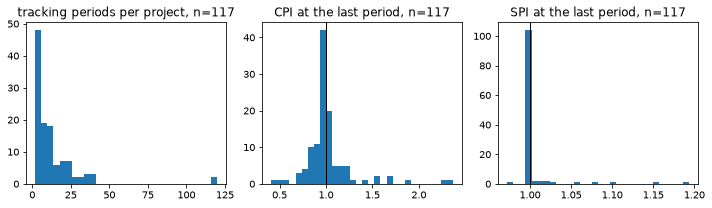

tracking periods per project: median 8, max 120
periods named 'Actual Schedule' (is_final): 37
last periods with EV >= 99 % of BAC (project finished): 115 of 117
last periods with CPI < 1: 73, with AC > 1.01 x BAC (spent over 1 % more than the budget): 66
last periods with SPI > 1.001 (finished early): 14


,cpi,spi,spi_t
count,117.00,117.00,117.00
mean,1.02,1.01,0.92
std,0.27,0.03,0.15
min,0.41,0.97,0.50
25%,0.93,1.00,0.85
50%,0.98,1.00,0.95
75%,1.01,1.00,1.00
max,2.37,1.19,1.50


In [6]:
periods = tracking.groupby("project_id").size()
last = tracking.sort_values("period").groupby("project_id").tail(1)
last = last.merge(projects[["project_id", "bac"]], on="project_id", how="left")
fig, axes = plt.subplots(1, 3)
axes[0].hist(periods, bins=30)
axes[0].set_title(f"tracking periods per project, n={len(periods)}")
for ax, col in [(axes[1], "cpi"), (axes[2], "spi")]:
    values = last[col].dropna()
    ax.hist(values, bins=30)
    ax.axvline(1.0, color="black", linewidth=1)
    ax.set_title(f"{col.upper()} at the last period, n={len(values)}")
plt.tight_layout()
plt.show()
print(f"tracking periods per project: median {periods.median():.0f}, max {periods.max()}")
print(f"periods named 'Actual Schedule' (is_final): {int(tracking['is_final'].sum())}")
done = int((last["ev"] >= 0.99 * last["bac"]).sum())
print(f"last periods with EV >= 99 % of BAC (project finished): {done} of {len(last)}")
print(
    f"last periods with CPI < 1: {int((last['cpi'] < 1).sum())}, "
    f"with AC > 1.01 x BAC (spent over 1 % more than the budget): "
    f"{int((last['ac'] > 1.01 * last['bac']).sum())}"
)
print(f"last periods with SPI > 1.001 (finished early): {int((last['spi'] > 1.001).sum())}")
last[["cpi", "spi", "spi_t"]].describe().round(2)

## 4. Sample records

The first group A project (tracking ready): its summary row, its first leaf activities and its
tracking periods. Source: Ghent DSLIB v3.4 (citation above).

In [7]:
sample_id = projects.loc[projects["group"] == "A", "project_id"].iloc[0]
# `submitted_by` (a person's name) is left out of the sample
sample = projects.loc[projects["project_id"] == sample_id].drop(columns="submitted_by")
sample.T.rename(columns=lambda _: sample_id)

,C2011-05
project_id,C2011-05
name,Telecom System Agnes
sector,IT
keywords,Medical; Nurse Center
group,A
completeness_baseline,green
completeness_risk,yellow
completeness_control,green
n_activities,21
planned_duration_days,43.0


In [8]:
activity_cols = [
    "activity_id",
    "name",
    "wbs",
    "baseline_start",
    "duration_raw",
    "duration_days",
    "total_cost",
]
leaf.loc[leaf["project_id"] == sample_id, activity_cols].head(5)

,activity_id,name,wbs,baseline_start,duration_raw,duration_days,total_cost
356,1,order license,1.1,2011-05-18 08:00:00,3d,3.0,2400.0
357,2,final order,1.2,2011-05-23 08:00:00,1d,1.0,800.0
358,3,ordering equipment,1.3,2011-05-24 08:00:00,1d,1.0,440.0
359,4,discussion list,1.4,2011-06-10 10:00:00,1d,1.0,800.0
360,5,final discussion list,1.5,2011-06-24 10:00:00,1d,1.0,800.0


In [9]:
tracking_cols = ["period", "period_name", "status_date", "pv", "ev", "ac", "cpi", "spi"]
tracking.loc[tracking["project_id"] == sample_id, tracking_cols]

,period,period_name,status_date,pv,ev,ac,cpi,spi
0,1,"24/05, 2011",2011-05-24 17:00:00,13526.639648,13526.639648,13526.639648,1.0,1.000000
1,2,"20/06, 2011",2011-06-20 17:00:00,115357.889734,115357.890010,115357.889734,1.0,1.000000
2,3,"27/06, 2011",2011-06-27 17:00:00,143433.170007,129405.889813,129405.889734,1.0,0.902203
3,4,"12/07, 2011",2011-07-12 17:00:00,176069.270056,166619.970017,166619.970007,1.0,0.946332
4,5,Actual Schedule,2011-07-29 17:00:00,180485.270056,180485.270056,180485.270056,1.0,1.000000


## 5. Findings

Every number below is computed from the tables above in this run.

In [10]:
construction = projects["sector"].fillna("").str.startswith("Construction")
n_constr = int(construction.sum())
n_constr_a = int((construction & (projects["group"] == "A")).sum())
size = projects["n_activities"]
over_budget = int((last["cpi"] < 1).sum())
over_budget_ac = int((last["ac"] > 1.01 * last["bac"]).sum())
top_issue = issue_table["issues"].idxmax()
spi_t_median = last["spi_t"].median()
findings = [
    f"{groups['A']} of {len(projects)} projects (group A) have earned-value tracking ready; "
    f"{groups['B']} more (group B) need PV/EV computed from raw progress (roadmap Phase 4).",
    f"{n_constr} projects are construction ({n_constr_a} of them in group A); the rest are "
    "other sectors (table in part 1). A construction-only model has less data.",
    f"Project size spans {size.min()}-{size.max()} activities (median {size.median():.0f}); "
    "budgets need a log scale or per-project ratios (CPI, SPI) as model features, not raw euros.",
    f"Tracking periods per project: median {periods.median():.0f}, max {periods.max()}; "
    "an early-warning model must handle very different series lengths.",
    f"Only {int(tracking['is_final'].sum())} periods are named 'Actual Schedule', but in "
    f"{done} of {len(last)} projects the last period has EV >= 99 % of BAC: the last period "
    "is a better 'final' value than that flag.",
    f"{over_budget} of {last['cpi'].notna().sum()} tracked projects end with CPI < 1 at their "
    f"last period ({over_budget_ac} spent over 1 % more than their BAC): cost overrun is not "
    "rare in this data.",
    f"SPI at the last period has median {last['spi'].median():.2f}: at completion EV = BAC = "
    "PV, so SPI returns to 1 whatever the delay (above 1 only for early finishers). SPI(t) "
    f"(median {spi_t_median:.2f}) is the schedule measure to use.",
    f"{len(issues)} loader issues in {issues['project_id'].nunique()} projects; the largest "
    f"kind, '{top_issue}' ({issue_table['issues'].max()}), comes from "
    f"{issue_table.loc[top_issue, 'projects']} project(s). "
    f"{int(projects['bac'].isna().sum())} projects have no BAC.",
]
for i, text in enumerate(findings, 1):
    print(f"{i}. {text}")

1. 117 of 231 projects (group A) have earned-value tracking ready; 41 more (group B) need PV/EV computed from raw progress (roadmap Phase 4).
2. 163 projects are construction (81 of them in group A); the rest are other sectors (table in part 1). A construction-only model has less data.
3. Project size spans 8-1796 activities (median 38); budgets need a log scale or per-project ratios (CPI, SPI) as model features, not raw euros.
4. Tracking periods per project: median 8, max 120; an early-warning model must handle very different series lengths.
5. Only 37 periods are named 'Actual Schedule', but in 115 of 117 projects the last period has EV >= 99 % of BAC: the last period is a better 'final' value than that flag.
6. 73 of 117 tracked projects end with CPI < 1 at their last period (66 spent over 1 % more than their BAC): cost overrun is not rare in this data.
7. SPI at the last period has median 1.00: at completion EV = BAC = PV, so SPI returns to 1 whatever the delay (above 1 only for e